## Regional diversity and drivers using reanalysis data and validation using observed precipitation data

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [6]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [7]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [8]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [42]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.land

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax


def add_qk_bbox(ax, qk, q, patch_zorder):
    # --- Add a box around both arrow and label ---
    # Choose size & position in Axes fraction coordinates
    box_x, box_y = 1.03, 1.07   # lower-left corner of box
    box_w, box_h = 0.14, 0.05    # width & height of box

    rect = mpatches.FancyBboxPatch(
        (box_x, box_y), box_w, box_h,
        transform=ax.transAxes,
        boxstyle="square,pad=0.25",
        facecolor='white', edgecolor='black', alpha=1.0,
        zorder=patch_zorder, clip_on=True  # below text & arrow
    )
    ax.add_patch(rect)

    # Raise the quiverkey elements above the box
    qk.text.set_zorder(4)
    q.set_zorder(2)


def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            step = 6
            # q = axlist[i].quiver(x[::step, ::step], y[::step, ::step], u_wnd[i][::step, ::step], v_wnd[i][::step, ::step], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            q = axlist[i].quiver(x[::step, ::step], y[::step, ::step], u_wnd[i][::step, ::step], v_wnd[i][::step, ::step], scale_units='xy', scale=wind_scale, width=0.003, headwidth=3, headlength=4, headaxislength=3, color='k', pivot='middle', transform=ccrs.PlateCarree())
            if i == 0:
                qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
                add_qk_bbox(axlist[i], qk, q, patch_zorder=4)
            # qk.text.set_bbox(dict(facecolor='white', edgecolor='k', boxstyle='square,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

    return axlist



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    
    return ax

In [11]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [12]:
import sys

In [13]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [1]:
from functions import preproc_funcs as funcs

In [15]:
def calc_tele_diversity(precip, nino34, duration=30, gap=2):

    nt = precip.sizes["time"]
    indices = list(range(0, nt - duration, gap))

    regr_list, corr_list, pval_list = [], [], []
    ey = []

    for i in tqdm(indices, desc="Computing teleconnections"):

        x = nino34.isel(time=slice(i, i+duration))
        y = precip.isel(time=slice(i, i+duration))

        slope, corr, pval = funcs.get_all_metrics(x, y, dim="time")

        regr_list.append(slope.data)
        corr_list.append(corr.data)
        pval_list.append(pval.data)

        ey.append(int(nino34.time.dt.year[i + duration]))

    return xr.Dataset(
        dict(
            regr=("ey lat lon".split(), np.stack(regr_list)),
            corr=("ey lat lon".split(), np.stack(corr_list)),
            pval=("ey lat lon".split(), np.stack(pval_list)),
        ),
        coords=dict(
            lat=precip.lat,
            lon=precip.lon,
            ey=("ey", ey),
        ),
    )

In [16]:
tas_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/tas_regr_30.nc')
pr_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30.nc')
pr_regr_30_rean = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/pr_regr_30_rean.nc')

In [17]:
# psl_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/psl_regr_30.nc')
# uwnd10_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/uwnd_regr_30.nc')
# vwnd10_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/vwnd_regr_30.nc')
# hgt_regr_30 = xr.open_dataset('/g/data/if69/as8561/data/enso_tele_robustness/hgt_regr_30.nc')

In [18]:
ersst = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tos_ersstv5_g025_185401-202412.nc')
ersst['time'] = xr.cftime_range('1854-01-01', '2025-01-01', freq='1M')

hadisst = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tos_hadisst_g025_187001-202412.nc')
hadisst['time'] = xr.cftime_range('1870-01-01', '2025-01-01', freq='1M')

In [19]:
ersst_det = funcs.detrend_rolling_window(funcs.calc_anom(ersst, ersst.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
hadisst_det = funcs.detrend_rolling_window(funcs.calc_anom(hadisst, hadisst.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [20]:
tas_obs = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/tas_hadcrut.5.0.2.0_g025_185001-202402.nc')
tas_obs['time'] = xr.cftime_range('1850-01-01', '2024-03-01', freq='1M')
pr_obs = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/pr_gpcc.10.v2022_g025_189101-202402.nc')
pr_obs['time'] = xr.cftime_range('1891-01-01', '2024-03-01', freq='1M')

In [21]:
# pr_era5 = xr.open_mfdataset('/g/data/su28/MMLEAv2/observations/pr_era5_g025_194001-202312.nc')
# pr_era5['time'] = xr.cftime_range('1940-01-01', '2024-01-01', freq='1M')

In [22]:
pr_rean = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/precip/prate.mon.mean.nc')
pr_rean = pr_rean.rename(dict(prate = 'pr'))
pr_rean['time'] = xr.cftime_range('1836-01-01', '2016-01-01', freq='1M')
pr_rean

<xarray.Dataset> Size: 563MB
Dimensions:    (lat: 181, lon: 360, time: 2160, nbnds: 2)
Coordinates:
  * lat        (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 88.0 89.0 90.0
  * lon        (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time       (time) object 17kB 1836-01-31 00:00:00 ... 2015-12-31 00:00:00
Dimensions without coordinates: nbnds
Data variables:
    time_bnds  (time, nbnds) float64 35kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    pr         (time, lat, lon) float32 563MB dask.array<chunksize=(1, 181, 360), meta=np.ndarray>
Attributes: (12/24)
    Conventions:               CF-1.2
    title:                     Monthly NOAA/CIRES/DOE 20th Century Reanalysis V3
    comments:                  Data are from \nNOAA/CIRES/DOE 20th Century Re...
    standard_name_vocabulary:  NetCDF Climate and Forecast (CF) Metadata Conv...
    license:                   These data are available free of charge under ...
    spatial_resolution:        1.0 degree
    ...                        ...
    citation1:                 Slivinski, L. C, G. P. Compo, J. S. Whitaker, ...
    References:                https://www.psl.noaa.gov/data/gridded/data.20t...
    creator_name:              NOAA/PSL
    institution:               NOAA Physical Sciences Laboratory & CU/CIRES \...
    contact:                   psl.data@noaa.gov
    citation:                  Compo,G.P. <https://www.psl.noaa.gov/people/gi...

In [23]:
tas_obs_det = funcs.detrend_rolling_window(funcs.calc_anom(tas_obs, tas_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
pr_obs_det = funcs.detrend_rolling_window(funcs.calc_anom(pr_obs, pr_obs.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
pr_rean_det = funcs.detrend_rolling_window(funcs.calc_anom(pr_rean, pr_rean.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [24]:
psl = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/slp/prmsl.mon.mean.nc')
psl = psl.rename(dict(prmsl = 'psl'))
u10 = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/uwnd.10m.mon.mean.nc')
v10 = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/vwnd.10m.mon.mean.nc')
uwnd = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/uwnd.mon.mean_850_500_200.nc')
vwnd = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/wind/vwnd.mon.mean_850_500_200.nc')
hgt = xr.open_mfdataset('/g/data/if69/as8561/data/20CR/hgt/hgt.mon.mean_850_500_200.nc')

In [25]:
psl_det = funcs.detrend_rolling_window(funcs.calc_anom(psl, psl.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
u10_det = funcs.detrend_rolling_window(funcs.calc_anom(u10, u10.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
v10_det = funcs.detrend_rolling_window(funcs.calc_anom(v10, v10.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
uwnd_det = funcs.detrend_rolling_window(funcs.calc_anom(uwnd, uwnd.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)
vwnd_det = funcs.detrend_rolling_window(funcs.calc_anom(vwnd, vwnd.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

hgt_det = funcs.detrend_rolling_window(funcs.calc_anom(hgt, hgt.sel(time = slice('1960', '1990'))).resample(time = 'AS-JUN').mean('time'), window_size=15)

In [26]:
from dask.diagnostics import ProgressBar

In [27]:
with ProgressBar():
    ersst_det = ersst_det.tos.sel(time = slice('1900', '2014')).compute()
    hadisst_det = hadisst_det.tos.sel(time = slice('1900', '2014')).compute()
    tas_obs_det = tas_obs_det.tas.sel(time = slice('1900', '2014')).compute()
    pr_obs_det = pr_obs_det.pr.sel(time = slice('1900', '2014')).compute()
    pr_rean_det = pr_rean_det.pr.sel(time = slice('1900', '2014')).compute()

[                                        ] | 0% Completed | 260.54 us

[########################################] | 100% Completed | 2.25 ss
[########################################] | 100% Completed | 2.35 ss
[########################################] | 100% Completed | 13.99 s
[########################################] | 100% Completed | 3.27 ss
[########################################] | 100% Completed | 14.42 s


In [28]:
with ProgressBar():
    psl_det = psl_det.psl.sel(time = slice('1900', '2014')).compute()
    psl_det['time'] = pr_rean_det['time']
    uwnd_det = uwnd_det.uwnd.sel(time = slice('1900', '2014')).compute()
    uwnd_det['time'] = pr_rean_det['time']
    vwnd_det = vwnd_det.vwnd.sel(time = slice('1900', '2014')).compute()
    vwnd_det['time'] = pr_rean_det['time']
    u10_det = u10_det.uwnd.sel(time = slice('1900', '2014')).compute()
    u10_det['time'] = pr_rean_det['time']
    v10_det = v10_det.vwnd.sel(time = slice('1900', '2014')).compute()
    v10_det['time'] = pr_rean_det['time']
    hgt_det = hgt_det.hgt.sel(time = slice('1900', '2014')).compute()
    hgt_det['time'] = pr_rean_det['time']

[########################################] | 100% Completed | 14.55 s
[########################################] | 100% Completed | 74.79 s
[########################################] | 100% Completed | 74.26 s
[########################################] | 100% Completed | 13.76 s
[########################################] | 100% Completed | 16.06 s
[########################################] | 100% Completed | 75.72 s


In [29]:
pr_obs_std = pr_obs_det/pr_obs_det.std('time')
pr_rean_std = pr_rean_det/pr_rean_det.std('time')

In [30]:
pr_rean_std

<xarray.DataArray 'pr' (time: 115, lat: 181, lon: 360)> Size: 30MB
array([[[-0.282475  , -0.282475  , -0.282475  , ..., -0.282475  ,
         -0.282475  , -0.282475  ],
        [-0.15668504, -0.1503599 , -0.15630943, ..., -0.15972652,
         -0.15769635, -0.16777836],
        [-0.09038914, -0.09151712, -0.10576872, ..., -0.10767967,
         -0.11111484, -0.11233626],
        ...,
        [-0.10875204, -0.10709496, -0.11047538, ..., -0.10061551,
         -0.10568786, -0.11109946],
        [-0.20355771, -0.20261464, -0.19958377, ..., -0.19613436,
         -0.196644  , -0.19912545],
        [-0.24701141, -0.24701141, -0.24701141, ..., -0.24701141,
         -0.24701141, -0.24701141]],

       [[ 0.46080938,  0.46080938,  0.46080938, ...,  0.46080938,
          0.46080938,  0.46080938],
        [ 0.29817778,  0.3030413 ,  0.29455674, ...,  0.3074457 ,
          0.29914653,  0.30102062],
        [ 0.20668687,  0.21374084,  0.21157905, ...,  0.20880651,
          0.19600268,  0.20147993],
...
        [ 1.1457093 ,  1.1565455 ,  1.1787276 , ...,  1.0796652 ,
          1.1130645 ,  1.133194  ],
        [ 1.4977162 ,  1.5019453 ,  1.5047183 , ...,  1.4705197 ,
          1.4831054 ,  1.4861927 ],
        [ 1.7810166 ,  1.7810166 ,  1.7810166 , ...,  1.7810166 ,
          1.7810166 ,  1.7810166 ]],

       [[ 1.4870056 ,  1.4870056 ,  1.4870056 , ...,  1.4870056 ,
          1.4870056 ,  1.4870056 ],
        [ 1.2146847 ,  1.2215707 ,  1.2251503 , ...,  1.1953635 ,
          1.1907067 ,  1.2052119 ],
        [ 0.5425624 ,  0.54095423,  0.5724486 , ...,  0.515634  ,
          0.5244506 ,  0.5368324 ],
        ...,
        [ 2.4275744 ,  2.4337482 ,  2.4324756 , ...,  2.424981  ,
          2.4348595 ,  2.4265525 ],
        [ 2.412509  ,  2.4166374 ,  2.415178  , ...,  2.4056249 ,
          2.413907  ,  2.4092274 ],
        [ 1.7210498 ,  1.7210498 ,  1.7210498 , ...,  1.7210498 ,
          1.7210498 ,  1.7210498 ]]], dtype=float32)
Coordinates:
  * lat      (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 87.0 88.0 89.0 90.0
  * lon      (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * time     (time) object 920B 1900-06-01 00:00:00 ... 2014-06-01 00:00:00

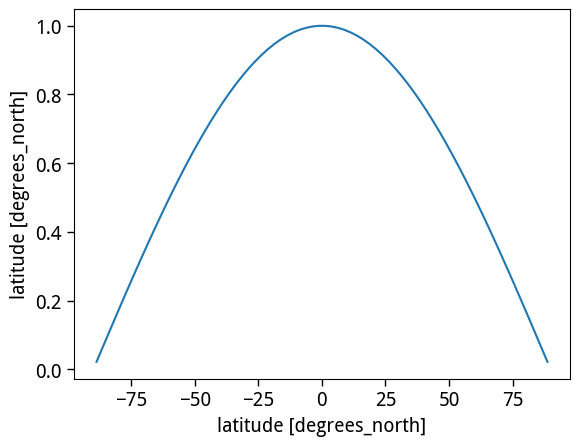

In [31]:
weights_obs = np.cos(np.deg2rad(hadisst_det.lat))
weights_obs.name = 'weights'
weights_obs.plot()

In [32]:
nino34_index_hadisst = hadisst_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_obs).mean(('lat', 'lon'))
nino34_index = nino34_index_hadisst
nino34_index_ersst = ersst_det.sel(lat = slice(-5, 5), lon = slice(-170+360, -120+360)).weighted(weights_obs).mean(('lat', 'lon'))

In [33]:
from tqdm.auto import tqdm

In [34]:
def calc_tele_diversity(precip, nino34, duration=30, gap=2):

    nt = precip.sizes["time"]
    indices = list(range(0, nt - duration, gap))

    regr_list, corr_list, pval_list = [], [], []
    ey = []

    for i in tqdm(indices, desc="Computing teleconnections"):

        x = nino34.isel(time=slice(i, i+duration))
        y = precip.isel(time=slice(i, i+duration))

        slope, corr, pval = funcs.get_all_metrics(x, y, dim="time")

        regr_list.append(slope.data)
        corr_list.append(corr.data)
        pval_list.append(pval.data)

        ey.append(int(nino34.time.dt.year[i + duration]))

    return xr.Dataset(
        dict(
            regr=("ey lat lon".split(), np.stack(regr_list)),
            corr=("ey lat lon".split(), np.stack(corr_list)),
            pval=("ey lat lon".split(), np.stack(pval_list)),
        ),
        coords=dict(
            lat=precip.lat,
            lon=precip.lon,
            ey=("ey", ey),
        ),
    )


def calc_tele_diversity_1d(precip, nino34, duration=30, gap=2):

    nt = precip.sizes["time"]
    indices = list(range(0, nt - duration, gap))

    regr_list, corr_list, pval_list = [], [], []
    ey = []

    for i in tqdm(indices, desc="Computing teleconnections"):

        x = nino34.isel(time=slice(i, i+duration))
        y = precip.isel(time=slice(i, i+duration))

        slope, corr, pval = funcs.get_all_metrics(x, y, dim="time")

        regr_list.append(slope.data)
        corr_list.append(corr.data)
        pval_list.append(pval.data)

        ey.append(int(nino34.time.dt.year[i + duration]))

    return xr.Dataset(
        dict(
            regr=("ey", np.stack(regr_list)),
            corr=("ey", np.stack(corr_list)),
            pval=("ey", np.stack(pval_list)),
        ),
        coords=dict(
            ey=("ey", ey),
        ),
    )


In [35]:
land_mask_obs = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_obs_std)
ar6_mask_obs = regionmask.defined_regions.ar6.land.mask_3D(pr_obs_std.where(land_mask_obs))

In [36]:
land_mask_rean = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(pr_rean_std)
ar6_mask_rean = regionmask.defined_regions.ar6.land.mask_3D(pr_rean_std.where(land_mask_rean))

In [37]:
land_mask_tas_obs = regionmask.defined_regions.natural_earth_v5_0_0.land_10.mask_3D(tas_obs_det)
ar6_mask_tas_obs = regionmask.defined_regions.ar6.land.mask_3D(tas_obs_det.where(land_mask_tas_obs))

In [38]:
weights_pr_obs = np.cos(np.deg2rad(pr_obs_std.lat))
weights_pr_rean = np.cos(np.deg2rad(pr_rean_std.lat))

### australia

In [39]:
ar6_mask_rean.isel(region=[39, 40, 41, 42])

<xarray.DataArray 'mask' (region: 4, lat: 181, lon: 360)> Size: 261kB
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]])
Coordinates:
  * lat      (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 87.0 88.0 89.0 90.0
  * lon      (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
  * region   (region) int64 32B 39 40 41 42
    abbrevs  (region) <U4 64B 'NAU' 'CAU' 'EAU' 'SAU'
    names    (region) <U22 352B 'N.Australia' 'C.Australia' ... 'S.Australia'
Attributes:
    standard_name:  region

In [40]:
pr_rean_std = pr_rean_det/pr_rean_det.std('time')
out = calc_tele_diversity_1d(pr_rean_std.where(ar6_mask_rean.isel(region=[39,40,41,42])).weighted(weights_pr_rean).mean(('lat', 'lon', 'region')), nino34_index, duration=30, gap=2)
out

Computing teleconnections:   0%|          | 0/43 [00:00<?, ?it/s]

<xarray.Dataset> Size: 1kB
Dimensions:  (ey: 43)
Coordinates:
  * ey       (ey) int64 344B 1930 1932 1934 1936 1938 ... 2008 2010 2012 2014
Data variables:
    regr     (ey) float64 344B -0.2956 -0.3083 -0.3721 ... -0.5238 -0.5406
    corr     (ey) float64 344B -0.366 -0.4238 -0.4816 ... -0.6156 -0.5729
    pval     (ey) float64 344B 0.04671 0.0196 0.007041 ... 0.0002937 0.0009379

In [41]:
max_ey = int(out.ey.where(out.regr == out.regr.max(), drop=True))
min_ey = int(out.ey.where(out.regr == out.regr.min(), drop=True))
max_ey, min_ey

(1930, 1978)

In [ ]:

plot_list = [
    pr_regr_30_rean.regr.sel(ey = max_ey, drop=True),
    pr_regr_30_rean.regr.sel(ey = min_ey, drop=True),
    pr_regr_30_rean.regr.sel(ey = max_ey, drop=True) - pr_regr_30_rean.regr.sel(ey = min_ey, drop=True),
]

pval_list = [
    pr_regr_30_rean.pval.sel(ey = max_ey, drop=True),
    pr_regr_30_rean.pval.sel(ey = min_ey, drop=True),
    np.empty_like(pr_regr_30.regr.sel(ey=min_ey).to_numpy())
]

xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)


In [ ]:
axlist = plot_maps(xx, yy, plot_list, titles=['']*3, labels=['']*3, cmap='BrBG', levels=np.linspace(-2, 2, 21), pval = pval_list, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,5), land_mask_list = [], add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=150, central_latitude=-30), 
            cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)

for ax in axlist:
    regionmask.defined_regions.ar6.land[[39,40,41,42]].plot(
        ax=ax,
        line_kws=dict(color='black', lw=2.0, alpha=0.7),
        text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
        add_label=False, # Set to True to add text labels for regions
    )

TypeError: Dimensions of C (43, 180, 360) should be one smaller than X(360) and Y(181) while using shading='flat' see help(pcolor)

In [ ]:

plot_list = [
    pr_
    pr_regr_30_rean.regr.sel(ey = min_ey, drop=True),
    pr_regr_30_rean.regr.sel(ey = max_ey, drop=True) - pr_regr_30_rean.regr.sel(ey = min_ey, drop=True),
]

pval_list = [
    pr_regr_30_rean.pval.sel(ey = max_ey, drop=True),
    pr_regr_30_rean.pval.sel(ey = min_ey, drop=True),
    np.empty_like(pr_regr_30.regr.to_numpy())
]

xx, yy = np.meshgrid(plot_list[0].lon, plot_list[0].lat)


/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

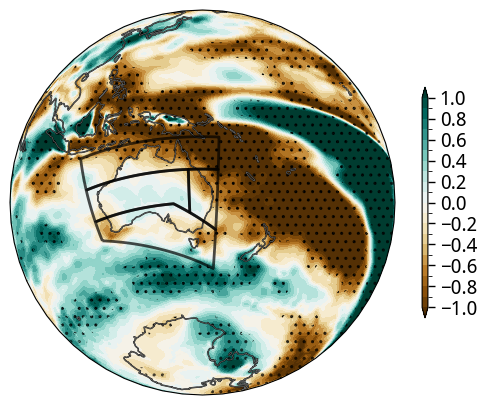

In [ ]:
zz = pr_regr_30_rean.regr.sel(ey = max_ey, drop=True)
pval = pr_regr_30_rean.pval.sel(ey = max_ey, drop=True)
xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=150, central_latitude=-30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[39,40,41,42]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

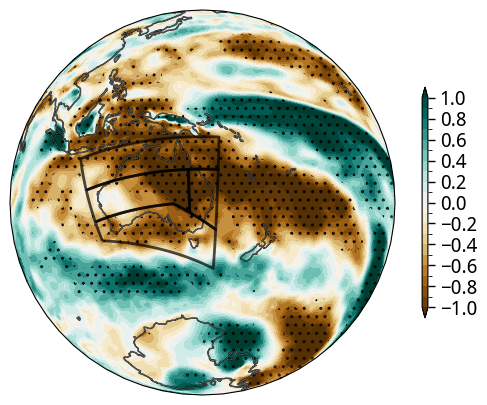

In [ ]:
zz = pr_regr_30_rean.regr.sel(ey = min_ey, drop=True)
pval = pr_regr_30_rean.pval.sel(ey = min_ey, drop=True)
xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=150, central_latitude=-30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)

regionmask.defined_regions.ar6.land[[39, 40, 41, 42]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

In [ ]:
n34 = 

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

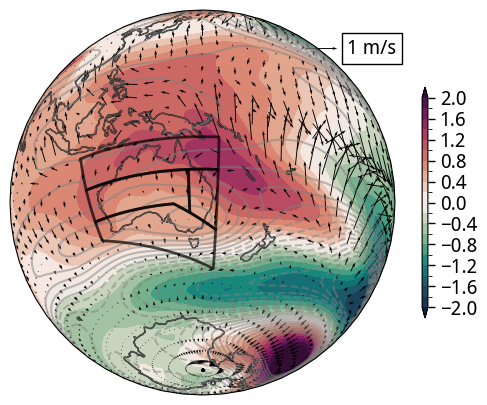

In [59]:
zz = psl_regr_30.regr.sel(ey = max_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = max_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = max_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = max_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = max_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-2, 2, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=12, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-20, 20, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=150, central_latitude=-30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[39, 40, 41, 42]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/cartopy/crs.py:547: UserWarning: Some vectors at source domain corners may not have been transformed correctly
  warnings.warn('Some vectors at source domain corners '
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

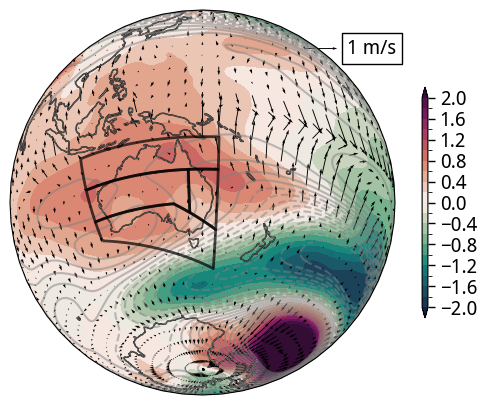

In [60]:
zz = psl_regr_30.regr.sel(ey = min_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = min_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = min_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = min_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = min_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-2, 2, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=12, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-20, 20, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=150, central_latitude=-30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[39, 40, 41, 42]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

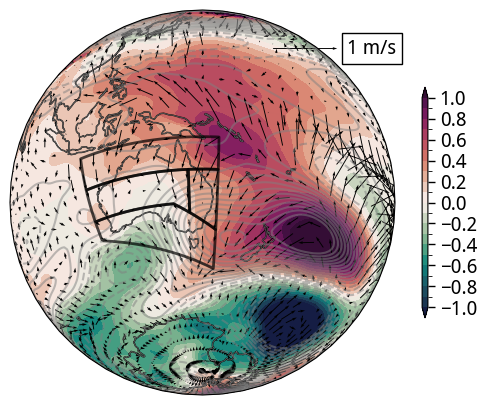

In [61]:
zz = psl_regr_30.regr.sel(ey = max_ey, drop=True) - psl_regr_30.regr.sel(ey = min_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = max_ey, drop=True) - hgt_regr_30.regr.sel(ey = min_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = max_ey, drop=True) - uwnd_regr_30.regr.sel(ey = min_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = max_ey, drop=True) - vwnd_regr_30.regr.sel(ey = min_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = max_ey, drop=True) - psl_regr_30.pval.sel(ey = min_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-1, 1, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=6, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-10, 10, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=150, central_latitude=-30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[39, 40, 41, 42]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

### south asia

In [150]:
ar6_mask_rean.isel(region=37)

<xarray.DataArray 'mask' (lat: 181, lon: 360)> Size: 65kB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])
Coordinates:
  * lat      (lat) float32 724B -90.0 -89.0 -88.0 -87.0 ... 87.0 88.0 89.0 90.0
  * lon      (lon) float32 1kB 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
    region   int64 8B 37
    abbrevs  <U4 16B 'SAS'
    names    <U22 88B 'S.Asia'
Attributes:
    standard_name:  region

In [148]:
pr_rean_std = pr_rean_det/pr_rean_det.std('time')
out = calc_tele_diversity_1d(pr_rean_std.where(ar6_mask_rean.isel(region=[37])).weighted(weights_pr_rean).mean(('lat', 'lon', 'region')), nino34_index, duration=30, gap=2)
out

Computing teleconnections:   0%|          | 0/43 [00:00<?, ?it/s]

<xarray.Dataset> Size: 1kB
Dimensions:  (ey: 43)
Coordinates:
  * ey       (ey) int64 344B 1930 1932 1934 1936 1938 ... 2008 2010 2012 2014
Data variables:
    regr     (ey) float64 344B -0.3656 -0.3647 -0.4016 ... -0.3833 -0.3494
    corr     (ey) float64 344B -0.3575 -0.3873 -0.4127 ... -0.5978 -0.5706
    pval     (ey) float64 344B 0.05243 0.03446 0.02343 ... 0.000486 0.0009921

In [151]:
max_ey = int(out.ey.where(out.regr == out.regr.max(), drop=True))
min_ey = int(out.ey.where(out.regr == out.regr.min(), drop=True))
max_ey, min_ey

(1952, 1940)

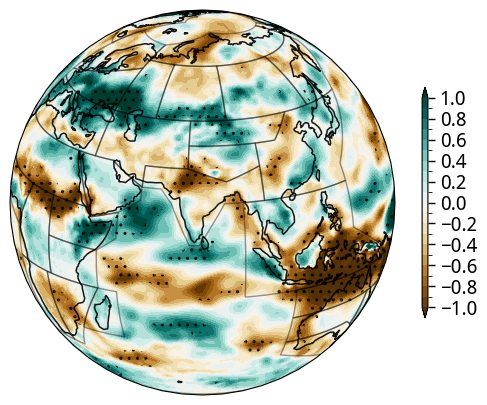

In [152]:
zz = pr_regr_30_rean.regr.sel(ey = max_ey, drop=True)
pval = pr_regr_30_rean.pval.sel(ey = max_ey, drop=True)
xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=80, central_latitude=20), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

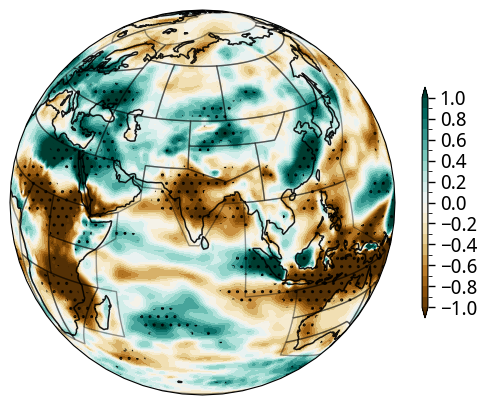

In [153]:
zz = pr_regr_30_rean.regr.sel(ey = min_ey, drop=True)
pval = pr_regr_30_rean.pval.sel(ey = min_ey, drop=True)
xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=80, central_latitude=20), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=True, auto_aspect=False)

### United States

In [1]:
ar6_mask_rean.isel(region=[3,4,6])

NameError: name 'ar6_mask_rean' is not defined

In [66]:
pr_rean_std = pr_rean_det/pr_rean_det.std('time')
out = calc_tele_diversity_1d(pr_rean_std.where(ar6_mask_rean.isel(region=[3,4,6])).weighted(weights_pr_rean).mean(('lat', 'lon', 'region')), nino34_index, duration=30, gap=2)
out

Computing teleconnections:   0%|          | 0/43 [00:00<?, ?it/s]

<xarray.Dataset> Size: 1kB
Dimensions:  (ey: 43)
Coordinates:
  * ey       (ey) int64 344B 1930 1932 1934 1936 1938 ... 2008 2010 2012 2014
Data variables:
    regr     (ey) float64 344B 0.4168 0.3676 0.2895 ... 0.2396 0.2475 0.2171
    corr     (ey) float64 344B 0.5444 0.5146 0.4127 ... 0.4825 0.4923 0.4082
    pval     (ey) float64 344B 0.001871 0.003622 0.02343 ... 0.005716 0.02512

In [67]:
max_ey = int(out.ey.where(out.regr == out.regr.max(), drop=True))
min_ey = int(out.ey.where(out.regr == out.regr.min(), drop=True))
max_ey, min_ey

(1930, 1988)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

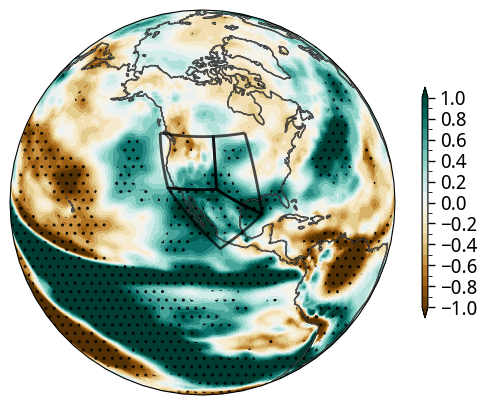

In [68]:
zz = pr_regr_30_rean.regr.sel(ey = max_ey, drop=True)
zc = psl_regr_30.regr.sel(ey = max_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = max_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = max_ey, drop=True)
pval = pr_regr_30_rean.pval.sel(ey = max_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=zu, v_wnd=zv, wind_scale=8, draw_contour=False, contour_data=[], contour_levels=np.linspace(-4, 4, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3,4,6]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

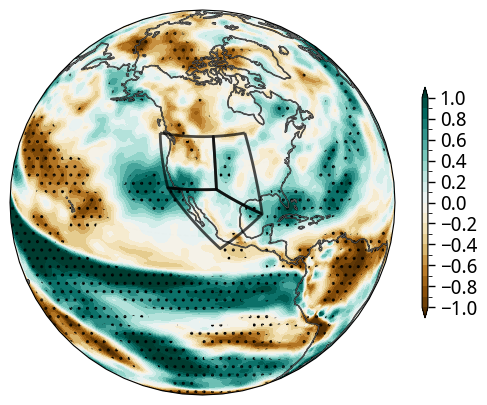

In [69]:
zz = pr_regr_30_rean.regr.sel(ey = min_ey, drop=True)
# zc = psl_regr_30.regr.sel(ey = min_ey, drop=True)
# zu = uwnd_regr_30.regr.sel(ey = min_ey, drop=True)
# zv = vwnd_regr_30.regr.sel(ey = min_ey, drop=True)
pval = pr_regr_30_rean.pval.sel(ey = min_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='BrBG', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=zu, v_wnd=zv, wind_scale=8, draw_contour=False, contour_data=[], contour_levels=np.linspace(-4, 4, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3,4,6]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

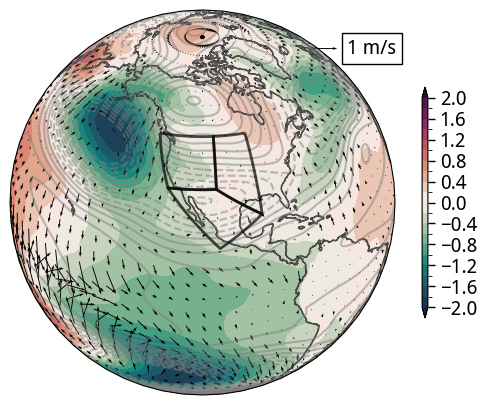

In [73]:
zz = psl_regr_30.regr.sel(ey = max_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = max_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = max_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = max_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = max_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-2, 2, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=15, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-20, 20, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3,4,6]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/cartopy/crs.py:547: UserWarning: Some vectors at source domain corners may not have been transformed correctly
  warnings.warn('Some vectors at source domain corners '
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

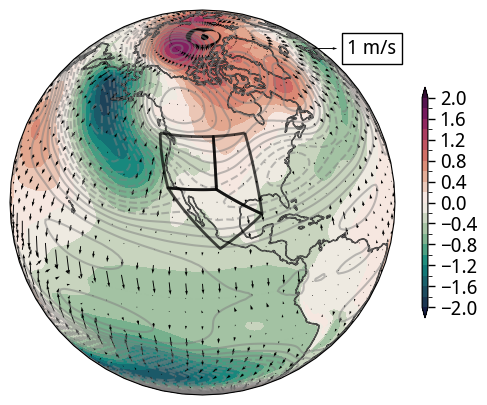

In [74]:
zz = psl_regr_30.regr.sel(ey = min_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = min_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = min_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = min_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = min_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-2, 2, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=15, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-20, 20, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3,4,6]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/cartopy/crs.py:547: UserWarning: Some vectors at source domain corners may not have been transformed correctly
  warnings.warn('Some vectors at source domain corners '
/g/data/xp65/public/apps/med_conda/envs/analysis3-25.09/lib/python3.11/site-packages/regionmask/core/plot.py:116: RuntimeWarning: 'text_kws' are passed but 'add_label' is False.
  warnings.warn(


<GeoAxes: >

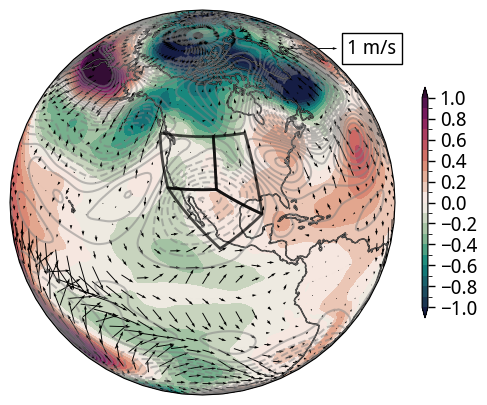

In [75]:
zz = psl_regr_30.regr.sel(ey = max_ey, drop=True) - psl_regr_30.regr.sel(ey = min_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = max_ey, drop=True) - hgt_regr_30.regr.sel(ey = min_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = max_ey, drop=True) - uwnd_regr_30.regr.sel(ey = min_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = max_ey, drop=True) - vwnd_regr_30.regr.sel(ey = min_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = max_ey, drop=True) - psl_regr_30.pval.sel(ey = min_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-1, 1, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=8, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-10, 10, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3,4,6]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=2.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

In [130]:
weights_tas_obs = np.cos(np.deg2rad(tas_obs_det.lat))

In [131]:
out = calc_tele_diversity_1d(tas_obs_det.where(ar6_mask_tas_obs.isel(region=[1])).weighted(weights_tas_obs).mean(('lat', 'lon', 'region')), nino34_index, duration=30, gap=2)
out

Computing teleconnections:   0%|          | 0/43 [00:00<?, ?it/s]

<xarray.Dataset> Size: 1kB
Dimensions:  (ey: 43)
Coordinates:
  * ey       (ey) int64 344B 1930 1932 1934 1936 1938 ... 2008 2010 2012 2014
Data variables:
    regr     (ey) float64 344B 0.6064 0.6483 0.784 ... 0.2454 0.2481 0.3413
    corr     (ey) float64 344B 0.588 0.6423 0.7201 ... 0.4118 0.4514 0.5502
    pval     (ey) float64 344B 0.0006332 0.00013 7.239e-06 ... 0.01229 0.001634

In [132]:
max_ey = int(out.ey.where(out.regr == out.regr.max(), drop=True))
min_ey = int(out.ey.where(out.regr == out.regr.min(), drop=True))
max_ey, min_ey

(1934, 1992)

<GeoAxes: >

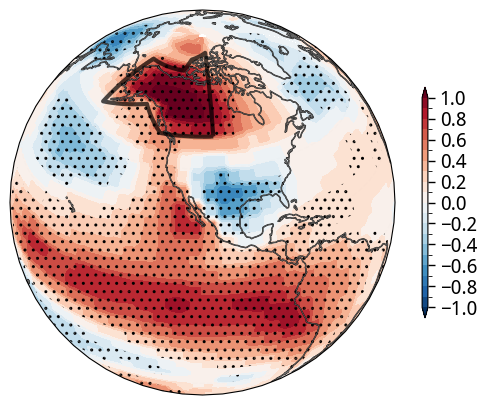

In [133]:
zz = tas_regr_30.regr.sel(ey = max_ey, drop=True)
pval = tas_regr_30.pval.sel(ey = max_ey, drop=True)
xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='RdBu_r', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[1]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=3.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

<GeoAxes: >

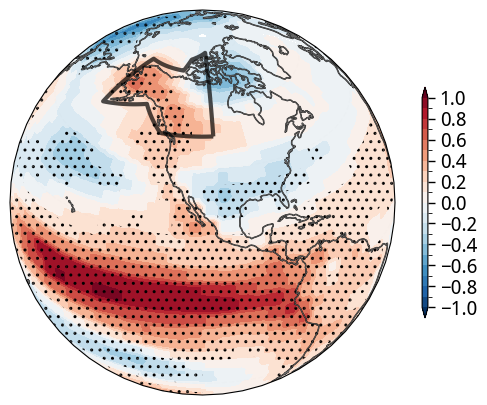

In [134]:
zz = tas_regr_30.regr.sel(ey = min_ey, drop=True)
pval = tas_regr_30.pval.sel(ey = min_ey, drop=True)
xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, zz, title='', label='', cmap='RdBu_r', levels=np.linspace(-1, 1, 21), add_sign=True, pval = pval, draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[1]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=3.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

<GeoAxes: >

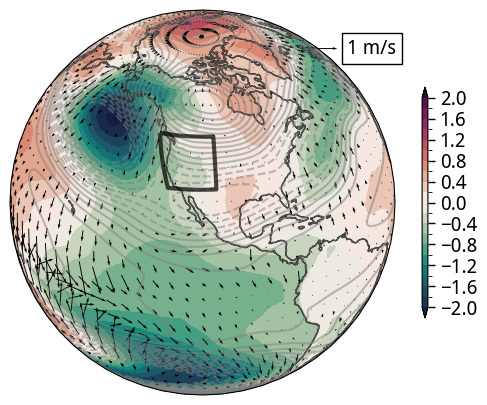

In [121]:
zz = psl_regr_30.regr.sel(ey = max_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = max_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = max_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = max_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = max_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-2, 2, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=15, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-20, 20, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=3.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

<GeoAxes: >

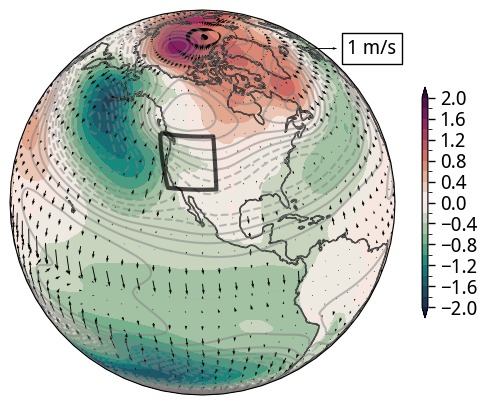

In [122]:
zz = psl_regr_30.regr.sel(ey = min_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = min_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = min_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = min_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = min_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-2, 2, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=15, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-20, 20, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=3.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)

<GeoAxes: >

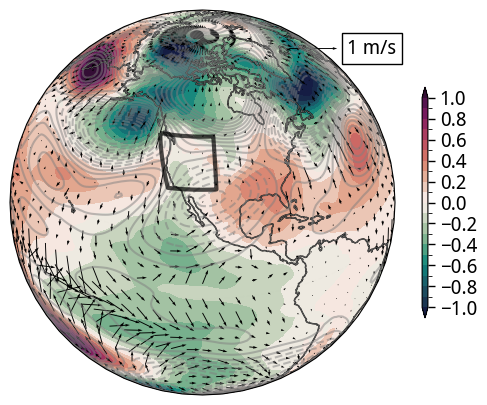

In [136]:
zz = psl_regr_30.regr.sel(ey = max_ey, drop=True) - psl_regr_30.regr.sel(ey = min_ey, drop=True)
zc = hgt_regr_30.regr.sel(ey = max_ey, drop=True) - hgt_regr_30.regr.sel(ey = min_ey, drop=True)
zu = uwnd_regr_30.regr.sel(ey = max_ey, drop=True) - uwnd_regr_30.regr.sel(ey = min_ey, drop=True)
zv = vwnd_regr_30.regr.sel(ey = max_ey, drop=True) - vwnd_regr_30.regr.sel(ey = min_ey, drop=True)
pval = psl_regr_30.pval.sel(ey = max_ey, drop=True) - psl_regr_30.pval.sel(ey = min_ey, drop=True)

xx, yy = np.meshgrid(zz.lon, zz.lat)

ax = plot_single_map(xx, yy, (zz/100), title='', label='', cmap=cmocean.cm.curl, levels=np.linspace(-1, 1, 21), add_sign=False, pval = pval, draw_winds=True, u_wnd=zu, v_wnd=zv, wind_scale=8, draw_contour=True, contour_data=zc, contour_levels=np.linspace(-10, 10, 21), contour_colors='gray', 
                figsize=(7,5), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'sig', proj=ccrs.Orthographic(central_longitude=250, central_latitude=30), 
                cbar_kwargs=dict(orientation='vertical', label='', aspect=40, shrink=0.6, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False)


regionmask.defined_regions.ar6.land[[3]].plot(
    ax=ax,
    line_kws=dict(color='black', lw=3.0, alpha=0.7),
    text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
    add_label=False, # Set to True to add text labels for regions
)